# SA–LSTM vs TPE–LSTM — 6 bộ đầu vào, chỉ residual

Mở rộng từ notebook người dùng đã chạy. Từng bộ FS01–FS06 tìm siêu tham số SA/TPE riêng trên train/validation của 80/20 expanding, rồi khóa cấu hình để đánh giá 6 bối cảnh. Giữ kiến trúc, residual, lookback 22, horizon 1 và ngân sách của bản gốc.

Đối chiếu code V20/V21/V22 và báo cáo Mythos: FS01 Copper; FS02 Copper/WTI/Gold/Silver (Paper3+Cu); FS03 WTI/Gold/Silver (Paper3−Cu); FS04 Copper/Aluminium/Tin/Silver/Gold (Legacy14+Cu); FS05 Aluminium/Tin/Silver/Gold (Legacy14−Cu); FS06 Copper/Aluminium/Tin/WTI (WTI+Cu). Mã FS là quy ước thống nhất ở notebook này; notebook nguồn dùng tên bộ biến.

Mọi bộ dùng cùng dòng dữ liệu sau làm sạch, cùng ngày chia, cùng ngân sách tìm kiếm. Mô hình học delta và cộng giá Copper(t−1) thật khi hoàn nguyên: kể cả FS03/FS05 không đưa Copper vào mạng, đầu ra residual vẫn dùng giá phiên trước. Không coi chúng là mô hình hoàn toàn không dùng Copper. SA ở V21–V23 học mức giá trực tiếp; bản này giữ SA/TPE cùng residual theo yêu cầu trước, nên không phải tái hiện nguyên xi nhánh SA nguồn.

Mặc định QUICK_MODE để kiểm tra luồng; đổi FULL_MODE khi chạy chính. Notebook mới chưa có kết quả huấn luyện. Không tự chọn biến bằng Spearman; đây là đối chiếu các bộ biến cố định.


## 1. Giao thức

- 6 bộ biến × 6 bối cảnh × 2 phương pháp × số seed. Một seed: **36 cặp so sánh, 72 final fits**.
- FULL_MODE: 16 trials/phương pháp/bộ/seed → **192 search fits + 72 final fits = 264 fits** với seed 42.
- QUICK_MODE: 4 trials/phương pháp/bộ/seed → **48 search fits + 72 final fits = 120 fits**. Quick vẫn chạy toàn bộ bộ biến nên có thể mất thời gian; có thể giảm ACTIVE_FEATURE_SETS để kiểm tra một phần.
- Ratio 80%, 92.5%, 95%: expanding. Ratio 90%: expanding, rolling_756, recency_weighted. Validation là 10% phần trước test.
- Các nhãn expanding/rolling ở notebook này chỉ thay dữ liệu train của từng split; **không tái huấn luyện định kỳ trong test** như notebook walk-forward của Quân.
- Tuning 80/20 expanding riêng theo bộ biến và seed, không xem test. Các HP chuyển sang bối cảnh còn lại; không refit train+validation.
- Seed 42 chưa đánh giá được độ ổn định; test giữa các ratio chồng lấn. Không chọn bộ biến cuối cùng bằng test rồi báo chính test đó như đánh giá độc lập.


In [1]:
import importlib.util,subprocess,sys
if importlib.util.find_spec('optuna') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet','optuna>=4.2,<6'])


In [2]:
from pathlib import Path
import gc,json,time,math,hashlib,zipfile,platform
from datetime import datetime,timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from IPython.display import display,FileLink
import tensorflow as tf
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu,True)
    except RuntimeError: pass
print('TensorFlow:',tf.__version__,'Optuna:',optuna.__version__,'GPU:',tf.config.list_physical_devices('GPU'),flush=True)


TensorFlow: 2.21.0 Optuna: 5.1.0 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
MODE = 'FULL_MODE'
CSV_PATH = '/kaggle/input/datasets/thanhcong21206/ptdlkd-doan/dataset_9_commodities_daily.csv'
DATA_FILENAME = 'dataset_9_commodities_daily.csv'
FEATURE_SETS = {
    'FS01': ['Copper'],
    'FS02': ['Copper', 'WTI', 'Gold', 'Silver'],
    'FS03': ['WTI', 'Gold', 'Silver'],
    'FS04': ['Copper', 'Aluminium', 'Tin', 'Silver', 'Gold'],
    # Legacy14−Cu từ V21; WTI+Cu từ V22/V23.
    'FS05': ['Aluminium', 'Tin', 'Silver', 'Gold'],
    'FS06': ['Copper', 'Aluminium', 'Tin', 'WTI'],
}
ACTIVE_FEATURE_SETS = list(FEATURE_SETS)  # Có thể đặt ['FS04'] để thử nhanh.
assert ACTIVE_FEATURE_SETS and len(ACTIVE_FEATURE_SETS)==len(set(ACTIVE_FEATURE_SETS))
assert set(ACTIVE_FEATURE_SETS) <= set(FEATURE_SETS)
# Hợp các cột để làm sạch một lần, bảo đảm các bộ có cùng ngày dữ liệu.
FEATURES = list(dict.fromkeys(['Copper'] + [c for fs in ACTIVE_FEATURE_SETS for c in FEATURE_SETS[fs]]))
TARGET = 'Copper'
LOOKBACK, HORIZON = 22, 1
RATIOS = (0.80, 0.90, 0.925, 0.95)
PRIMARY_RATIO = 0.90
SCHEMES = ('expanding', 'rolling_756', 'recency_weighted')
SEEDS = [42]              # Muốn nghiên cứu độ ổn định: đặt [42, 710, 2024] TRƯỚC KHI CHẠY
FORECAST_MODES = ('residual',)
BASE_METHODS = ('sa_lstm_v22', 'tpe_lstm')
BATCH_SIZE = 64
MODE_CFG = {
    'QUICK_MODE': dict(epochs=5, search_epochs=3, sa_evals=4, earlystop=True),
    'FULL_MODE':  dict(epochs=100, search_epochs=15, sa_evals=16, earlystop=True),
}
assert MODE in MODE_CFG
CFG = MODE_CFG[MODE]
SPACE = {'units_1':(16,96), 'units_2':(24,160), 'learning_rate':(1e-5, 3e-3)}
INITIAL_HP = {'units_1':39, 'units_2':111, 'learning_rate':5e-5}
SEARCH_PATIENCE, FINAL_PATIENCE = 4, 9
assert min(RATIOS)==.80 and HORIZON==1 and len(set(SEEDS))==len(SEEDS)
ROOT = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else (Path('/content') if Path('/content').is_dir() else Path.cwd())
OUT = ROOT/'copper_sa_vs_tpe_six_feature_sets_no_naive'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT.mkdir(parents=True,exist_ok=False)
JOBS = [(ratio,scheme) for ratio in RATIOS for scheme in (SCHEMES if ratio==PRIMARY_RATIO else ('expanding',))]
METHOD_LABELS = [f'{method}_{mode}' for mode in FORECAST_MODES for method in BASE_METHODS]
print('Output:',OUT)
print(f'{MODE}: {len(ACTIVE_FEATURE_SETS)*len(BASE_METHODS)*len(FORECAST_MODES)*CFG["sa_evals"]*len(SEEDS)} search fits'
      f' + {len(ACTIVE_FEATURE_SETS)*len(BASE_METHODS)*len(FORECAST_MODES)*len(JOBS)*len(SEEDS)} final fits',flush=True)

display(pd.DataFrame([dict(feature_set=fs,n_features=len(FEATURE_SETS[fs]),features=', '.join(FEATURE_SETS[fs])) for fs in ACTIVE_FEATURE_SETS]))


Output: /kaggle/working/copper_sa_vs_tpe_six_feature_sets_no_naive/20261121T004726844166Z
FULL_MODE: 192 search fits + 72 final fits


,feature_set,n_features,features
0,FS01,1,Copper
1,FS02,4,"Copper, WTI, Gold, Silver"
2,FS03,3,"WTI, Gold, Silver"
3,FS04,5,"Copper, Aluminium, Tin, Silver, Gold"
4,FS05,4,"Aluminium, Tin, Silver, Gold"
5,FS06,4,"Copper, Aluminium, Tin, WTI"


## 2. Dữ liệu dùng chung

Làm sạch trên hợp các cột của các bộ đang bật để mọi bộ có cùng ngày train/validation/test. Không nội suy bằng tương lai. Chấp nhận WTI âm nếu CSV có giá dầu âm; Copper và giá kim loại phải dương.


In [4]:
def resolve_csv(csv_path, filename, input_root=Path('/kaggle/input')):
    """Ưu tiên đường dẫn chỉ định, sau đó tìm Kaggle/Colab/local; Colab cho upload."""
    if csv_path is not None:
        p=Path(csv_path).expanduser()
        if not p.is_file():
            raise FileNotFoundError(f'CSV_PATH không tồn tại: {p}. Đặt CSV_PATH=None nếu muốn tự tìm.')
        return p
    roots=[input_root,Path('/content'),Path.cwd(),Path('/mnt/data')]
    names=(filename,'commodities_9_daily.csv')
    found=[]
    for root in roots:
        if not root.is_dir():continue
        for name in names:
            found.extend(p.resolve() for p in root.rglob(name) if p.is_file())
    found=sorted(set(found))
    if len(found)==1:return found[0]
    if len(found)>1:
        raise FileNotFoundError(f'Tìm thấy nhiều CSV: {found}. Hãy đặt CSV_PATH cụ thể.')
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Không tìm thấy {names}. Upload file hoặc đặt CSV_PATH.')
    uploaded=files.upload()
    if len(uploaded)!=1:
        raise FileNotFoundError('Hãy upload đúng một file CSV và chạy lại cell này.')
    p=Path('/content')/next(iter(uploaded))
    if not p.is_file():p=Path(next(iter(uploaded)))
    if not p.is_file():raise FileNotFoundError(f'Không tìm thấy file mới upload: {p}')
    return p

def clean_data(raw):
    raw=raw.copy()
    raw.columns=[str(c).strip().lstrip('\ufeff') for c in raw.columns]
    aliases={f'Price_{key}':key for key in FEATURES}
    if raw.columns.duplicated().any() or any(a in raw.columns and b in raw.columns for a,b in aliases.items()):
        raise ValueError('Tên biến trùng/nhập nhằng.')
    raw=raw.rename(columns=aliases)
    required=['Date']+FEATURES
    missing=set(required)-set(raw.columns)
    if missing:raise ValueError(f'Thiếu cột: {missing}')
    raw=raw[required].copy()
    raw.Date=pd.to_datetime(raw.Date,errors='coerce',utc=True).dt.tz_convert(None).dt.normalize()
    if raw.Date.isna().any() or raw.Date.duplicated().any():raise ValueError('Ngày không hợp lệ hoặc trùng.')
    for key in FEATURES:raw[key]=pd.to_numeric(raw[key],errors='coerce')
    n=len(raw)
    data=raw.replace([np.inf,-np.inf],np.nan).dropna().sort_values('Date').reset_index(drop=True)
    if len(data)<=1000:raise ValueError('Cần hơn 1000 dòng hợp lệ theo giao thức V22.')
    positive_cols=[key for key in FEATURES if key!='WTI']
    if not (data[positive_cols]>0).all().all():raise ValueError('Giá kim loại <=0: kiểm tra nguồn CSV.')
    return data,dict(rows_source=n,rows_used=len(data),rows_removed=n-len(data),start=str(data.Date.min()),end=str(data.Date.max()))

DATA_PATH=resolve_csv(CSV_PATH,DATA_FILENAME)
data,quality=clean_data(pd.read_csv(DATA_PATH,encoding='utf-8-sig'))
data.to_csv(OUT/'dataset_snapshot.csv',index=False,encoding='utf-8-sig')
DATA_SHA=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
(OUT/'data_quality.json').write_text(json.dumps(quality,indent=2),encoding='utf-8')
print(DATA_PATH,quality,flush=True)
display(data.head())


/kaggle/input/datasets/thanhcong21206/ptdlkd-doan/dataset_9_commodities_daily.csv {'rows_source': 2710, 'rows_used': 2710, 'rows_removed': 0, 'start': '2016-01-13 00:00:00', 'end': '2026-11-13 00:00:00'}


,Date,Copper,WTI,Gold,Silver,Aluminium,Tin
0,2016-01-13,1.9560,30.48,1087.1,14.156,1462.5,13305.0
1,2016-01-14,1.9760,31.20,1073.6,13.748,1483.0,13260.0
2,2016-01-15,1.9435,29.42,1090.7,13.896,1473.0,13205.0
3,2016-01-19,1.9775,28.46,1090.7,14.121,1481.0,13225.0
4,2016-01-20,1.9595,26.55,1106.2,14.160,1469.0,13390.0


In [5]:
def make_context(frame, ratio, scheme='expanding', feature_set='FS04', val_fraction=0.10, include_test=False):
    n = len(frame)
    split = int(n * ratio)
    val_start = int(split * (1.0 - val_fraction))
    fit_start = 0 if scheme != 'rolling_756' else max(0, val_start - 756)
    cols = list(FEATURE_SETS[feature_set])
    assert LOOKBACK + 25 < val_start < split < n
    assert val_start - fit_start > LOOKBACK + 10
    # Train-only scaling: no future statistics leak into scaler.
    xsc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][cols])
    ysc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][[TARGET]])
    visible = frame if include_test else frame.iloc[:split]
    x = xsc.transform(visible[cols]).astype('float32')
    y = ysc.transform(visible[[TARGET]]).ravel().astype('float32')
    prev = np.r_[np.nan, y[:-1]]
    def block(start, end, restrict_train=False):
        indices = np.arange(max(start, LOOKBACK), end)
        if restrict_train:
            indices = indices[indices-LOOKBACK >= fit_start]
        X = np.stack([x[t-LOOKBACK:t] for t in indices]).astype('float32')
        return {'idx': indices, 'X': X, 'y': y[indices],
                'prev': prev[indices].astype('float32'),
                'date': frame.Date.iloc[indices].to_numpy()}
    tr = block(fit_start, val_start, True)
    va = block(val_start, split)
    te = block(split, n) if include_test else None
    assert tr['idx'][-1] < va['idx'][0]
    if include_test: assert va['idx'][-1] < te['idx'][0]
    assert xsc.n_samples_seen_ == val_start - fit_start
    assert len(tr['X']) > 0 and tr['X'].shape[1:] == (LOOKBACK, len(cols))
    # Last X timestamp is always t-1. Verify Copper only if included.
    if 'Copper' in cols:
        copper_col = cols.index('Copper')
        copper_raw_in_x = xsc.inverse_transform(x[tr['idx']-1])[:, copper_col]
        copper_true = frame.iloc[tr['idx']-1]['Copper'].to_numpy()
        assert np.allclose(copper_raw_in_x, copper_true, atol=1e-4)
    return {'train': tr, 'val': va, **({'test':te} if include_test else {}), 'xsc': xsc, 'ysc': ysc,
            'features': cols, 'feature_set': feature_set, 'horizon': 1,
            'ratio': float(ratio), 'scheme': scheme,
            'fit_start': fit_start, 'val_start': val_start, 'test_start': split}


In [6]:
audit=[]
for feature_set in ACTIVE_FEATURE_SETS:
    for ratio,scheme in JOBS:
        ctx=make_context(data,ratio,scheme,feature_set=feature_set)
        for part in ['train','val']:
            b=ctx[part]
            audit.append(dict(feature_set=feature_set,ratio=ratio,scheme=scheme,part=part,samples=len(b['idx']),
                              first_target=str(b['date'][0]),last_target=str(b['date'][-1])))
        test_start=ctx['test_start']
        audit.append(dict(feature_set=feature_set,ratio=ratio,scheme=scheme,part='test',samples=len(data)-test_start,
                          first_target=str(data.Date.iloc[test_start]),last_target=str(data.Date.iloc[-1])))
        assert 'test' not in ctx
split_df=pd.DataFrame(audit)
split_df.to_csv(OUT/'data_split_summary.csv',index=False)
display(split_df)
search_ctx=make_context(data,min(RATIOS),'expanding',feature_set=ACTIVE_FEATURE_SETS[0])
assert 'test' not in search_ctx


,feature_set,ratio,scheme,part,samples,first_target,last_target
0,FS01,0.800,expanding,train,1929,2016-02-16T00:00:00.000000000,2023-12-06T00:00:00.000000000
1,FS01,0.800,expanding,val,217,2023-12-07T00:00:00.000000000,2024-10-04T00:00:00.000000000
2,FS01,0.800,expanding,test,542,2024-10-07 00:00:00,2026-11-13 00:00:00
3,FS01,0.900,expanding,train,2173,2016-02-16T00:00:00.000000000,2024-11-12T00:00:00.000000000
4,FS01,0.900,expanding,val,244,2024-11-13T00:00:00.000000000,2025-10-28T00:00:00.000000000
...,...,...,...,...,...,...,...
103,FS06,0.925,expanding,val,251,2025-02-11T00:00:00.000000000,2026-01-29T00:00:00.000000000
104,FS06,0.925,expanding,test,204,2026-01-30 00:00:00,2026-11-13 00:00:00
105,FS06,0.950,expanding,train,2294,2016-02-16T00:00:00.000000000,2025-05-08T00:00:00.000000000
106,FS06,0.950,expanding,val,258,2025-05-09T00:00:00.000000000,2026-05-06T00:00:00.000000000


In [7]:
# Chỉ hỗ trợ mục tiêu residual; không có nhánh dự báo mức giá thuần.
def training_target(block, forecast_mode):
    if forecast_mode != 'residual':
        raise ValueError(f'Chỉ hỗ trợ residual: {forecast_mode}')
    return (block['y'] - block['prev']).astype('float32')


def restore_price_scaled(predicted_network_output, previous_copper_scaled, forecast_mode):
    if forecast_mode != 'residual':
        raise ValueError(f'Chỉ hỗ trợ residual: {forecast_mode}')
    pred=np.asarray(predicted_network_output,dtype='float64').reshape(-1)
    prev=np.asarray(previous_copper_scaled,dtype='float64').reshape(-1)
    if pred.shape != prev.shape:raise ValueError('Sai shape giữa prediction và prev Copper')
    return prev+pred

for blockname in ('train','val'):
    b=search_ctx[blockname]
    assert np.allclose(training_target(b,'residual')+b['prev'],b['y'],atol=1e-6)
    assert np.allclose(restore_price_scaled(training_target(b,'residual'),b['prev'],'residual'),b['y'],atol=1e-6)
assert search_ctx['train']['idx'].max()<search_ctx['val']['idx'].min()
assert search_ctx['xsc'].n_samples_seen_==search_ctx['val_start']-search_ctx['fit_start']
print('PASS: target residual, hoàn nguyên giá, shape và scaler train-only.')


PASS: target residual, hoàn nguyên giá, shape và scaler train-only.


## 3. LSTM residual

Kiến trúc và mục tiêu như bản gốc; kích thước input thay đổi theo bộ biến. Copper(t) không nằm trong input; cửa sổ chỉ chứa t−22…t−1.


In [8]:
def build_sa_lstm(input_shape, hp=None):
    """Kiến trúc SA-LSTM nhận siêu tham số linh hoạt do SA tìm kiếm (chỉ H=1, HP tìm mới riêng cho từng feature set)."""
    h = hp or INITIAL_HP
    u1 = int(h.get('units_1', 39))
    u2 = int(h.get('units_2', 111))
    lr = float(h.get('learning_rate', 5e-5))

    model = tf.keras.Sequential(name='Shared_V22_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(u1, return_sequences=True, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(u2, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(32, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse')
    return model

def sample_weights(length, scheme, half_life=252):
    if scheme != 'recency_weighted': return None
    ages = np.arange(length - 1, -1, -1, dtype='float64')
    w = np.exp(-np.log(2) * ages / half_life)
    return (w / w.mean()).astype('float32')


In [9]:
def train_config(ctx, hp, seed, epochs, patience, forecast_mode, model_path=None):
    tf.keras.backend.clear_session(); gc.collect(); tf.keras.utils.set_random_seed(int(seed))
    model = build_sa_lstm(ctx['train']['X'].shape[1:],hp)
    y_train_mode = training_target(ctx['train'],forecast_mode)
    y_val_mode = training_target(ctx['val'],forecast_mode)
    start=time.perf_counter()
    try:
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=patience,restore_best_weights=True),
                   tf.keras.callbacks.TerminateOnNaN()]
        history=model.fit(ctx['train']['X'],y_train_mode,
                          validation_data=(ctx['val']['X'],y_val_mode),
                          epochs=epochs,batch_size=BATCH_SIZE,shuffle=False,
                          sample_weight=sample_weights(len(ctx['train']['idx']),ctx['scheme']),
                          callbacks=callbacks,verbose=2 if MODE=='QUICK_MODE' else 0)
        if not all(np.isfinite(np.asarray(history.history[key])).all() for key in ['loss','val_loss']):
            raise FloatingPointError('Loss không hữu hạn; kiểm tra dữ liệu/hyperparameters')
        pred_val=model.predict(ctx['val']['X'],batch_size=BATCH_SIZE,verbose=0).ravel()
        if not np.isfinite(pred_val).all():raise FloatingPointError('Validation prediction không hữu hạn')
        score=float(mean_squared_error(y_val_mode,pred_val))
        fit=dict(val_mse=score,fit_seconds=time.perf_counter()-start,
                 epochs_run=len(history.history['loss']),history=history.history)
        if model_path is not None:model.save(model_path)
        return fit
    finally:
        del model;tf.keras.backend.clear_session();gc.collect()


## 4. Tìm siêu tham số riêng theo bộ biến

Mỗi bộ có hai lượt search SA/TPE ngân sách bằng nhau trên 80/20 expanding. Dùng cùng lịch trial seeds giữa hai phương pháp và giữa các bộ; FS04 giữ lịch seed như bản gốc. Kết quả ghi kèm feature_set và lưu riêng thư mục.


In [10]:
def clip_hp(h):
    return {'units_1':int(np.clip(round(h['units_1']), *SPACE['units_1'])),
            'units_2':int(np.clip(round(h['units_2']), *SPACE['units_2'])),
            'learning_rate':float(np.clip(h['learning_rate'], *SPACE['learning_rate']))}

def neighbor(h, rng, temp):
    # SA neighborhood defined in architecture space and log-LR space.
    h = dict(h); dim = rng.choice(['units_1','units_2','learning_rate'])
    if dim == 'learning_rate':
        h[dim] = float(h[dim] * np.exp(rng.normal(0, 0.65)))
    else:
        h[dim] = int(h[dim] + rng.choice([-1,1])*rng.choice([8,16,24]))
    return clip_hp(h)


In [11]:
def search_method(method, forecast_mode, ctx, folder, budget, search_seed):
    assert method in BASE_METHODS and forecast_mode in FORECAST_MODES
    model_key=f'{method}_{forecast_mode}'
    rows=[];start=time.perf_counter()
    def evaluate(hp,k):
        fit=train_config(ctx,hp,search_seed+k,CFG['search_epochs'],SEARCH_PATIENCE,
                         forecast_mode=forecast_mode)
        score=float(fit['val_mse'])
        if not np.isfinite(score):raise FloatingPointError('Validation MSE không hữu hạn')
        return score,fit
    def record(hp,score,fit,**extra):
        rows.append(dict(feature_set=ctx['feature_set'],method=method,forecast_mode=forecast_mode,model_key=model_key,
                         trial=len(rows)+1,val_mse_scaled=score,
                         best_val_mse_scaled=min([r['best_val_mse_scaled'] for r in rows]+[score]),
                         fit_seconds=fit['fit_seconds'],epochs_run=fit['epochs_run'],
                         trial_train_seed=search_seed+len(rows),elapsed_seconds=time.perf_counter()-start,
                         **hp,**extra))
        pd.DataFrame(rows).to_csv(folder/f'{model_key}_search_trials.csv',index=False)
        print(f'{model_key} [{len(rows)}/{budget}] val={score:.7g}, '
              f'best={rows[-1]["best_val_mse_scaled"]:.7g}',flush=True)
    if method=='sa_lstm_v22':
        rng=np.random.default_rng(search_seed)
        current=clip_hp(INITIAL_HP);current_loss=float('inf')
        for k in range(budget):
            temperature=float(max(.05,.88**k))
            hp=dict(current) if k==0 else neighbor(current,rng,temperature)
            score,fit=evaluate(hp,k)
            effective_temp=max(1e-8,temperature*max(score,current_loss if np.isfinite(current_loss) else score,1e-5))
            accepted=(score<=current_loss) or (rng.random()<np.exp(-max(0.,score-current_loss)/effective_temp))
            if accepted:current,current_loss=dict(hp),score
            record(hp,score,fit,temperature=temperature,accepted=bool(accepted))
    elif method=='tpe_lstm':
        study=optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler(
            seed=search_seed,n_startup_trials=min(10,max(2,budget//3)),multivariate=False),
            pruner=optuna.pruners.NopPruner())
        study.enqueue_trial(dict(INITIAL_HP))
        def objective(trial):
            hp=dict(units_1=trial.suggest_int('units_1',*SPACE['units_1']),
                    units_2=trial.suggest_int('units_2',*SPACE['units_2']),
                    learning_rate=trial.suggest_float('learning_rate',*SPACE['learning_rate'],log=True))
            score,fit=evaluate(hp,trial.number)
            record(hp,score,fit)
            return score
        study.optimize(objective,n_trials=budget,n_jobs=1)
    else:raise ValueError(method)
    assert len(rows)==budget
    best=min(rows,key=lambda r:r['val_mse_scaled'])
    return dict(feature_set=ctx['feature_set'],method=method,forecast_mode=forecast_mode,model_key=model_key,
                best_hp={key:best[key] for key in INITIAL_HP},
                best_val_mse_scaled=best['val_mse_scaled'],evaluations=len(rows),
                total_search_epochs=sum(r['epochs_run'] for r in rows),
                search_fit_seconds=sum(r['fit_seconds'] for r in rows),
                search_wall_seconds=time.perf_counter()-start),rows


In [12]:
manifest=dict(mode=MODE, config=CFG, features=FEATURES, feature_sets={fs:FEATURE_SETS[fs] for fs in ACTIVE_FEATURE_SETS}, target=TARGET,
              lookback=LOOKBACK,horizon=HORIZON, ratios=RATIOS,schemes=SCHEMES,
              jobs=JOBS,seeds=SEEDS,forecast_modes=FORECAST_MODES,base_methods=BASE_METHODS,
              space=SPACE, initial_hp=INITIAL_HP,search_reference_ratio=min(RATIOS),
              search_reference_scheme='expanding',dataset=str(DATA_PATH),dataset_sha256=DATA_SHA,
              python=platform.python_version(),versions={p:metadata.version(p) for p in
              ['tensorflow','optuna','numpy','pandas','scikit-learn']})
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
search_results=[];search_logs=[]
for feature_set in ACTIVE_FEATURE_SETS:
    search_ctx=make_context(data,min(RATIOS),'expanding',feature_set=feature_set)
    for seed_index,seed in enumerate(SEEDS):
        for mode_idx,forecast_mode in enumerate(FORECAST_MODES):
            folder=OUT/feature_set/f'seed_{seed}'/forecast_mode;folder.mkdir(parents=True,exist_ok=True)
            # SA/TPE của CÙNG mode dùng chung search seed/trial seeds.
            search_seed=12026+seed_index*1000
            order=list(BASE_METHODS if seed_index%2==0 else BASE_METHODS[::-1])
            for method in order:
                print(f'BEGIN search {feature_set} {method}_{forecast_mode}, seed={seed}',flush=True)
                best,logs=search_method(method,forecast_mode,search_ctx,folder,CFG['sa_evals'],search_seed)
                best['seed']=seed;best['folder']=str(folder);search_results.append(best)
                for row in logs:row['seed']=seed
                search_logs.extend(logs)
# Khóa HP cho hai phương pháp residual ở mọi seed TRƯỚC khi dự báo test.
(OUT/'locked_best_hyperparameters.json').write_text(json.dumps(search_results,indent=2),encoding='utf-8')
search_df=pd.DataFrame([{k:v for k,v in r.items() if k not in ['best_hp','folder']} for r in search_results])
search_df.to_csv(OUT/'search_comparison.csv',index=False)
search_trials=pd.DataFrame(search_logs);search_trials.to_csv(OUT/'all_search_trials.csv',index=False)
display(search_df)


BEGIN search FS01 sa_lstm_v22_residual, seed=42
sa_lstm_v22_residual [1/16] val=0.0003861061, best=0.0003861061
sa_lstm_v22_residual [2/16] val=0.0003816512, best=0.0003816512
sa_lstm_v22_residual [3/16] val=0.0003836656, best=0.0003816512
sa_lstm_v22_residual [4/16] val=0.0003841169, best=0.0003816512
sa_lstm_v22_residual [5/16] val=0.0003845206, best=0.0003816512
sa_lstm_v22_residual [6/16] val=0.0003827812, best=0.0003816512
sa_lstm_v22_residual [7/16] val=0.0003858652, best=0.0003816512
sa_lstm_v22_residual [8/16] val=0.000382009, best=0.0003816512
sa_lstm_v22_residual [9/16] val=0.0003821828, best=0.0003816512
sa_lstm_v22_residual [10/16] val=0.0003877412, best=0.0003816512
sa_lstm_v22_residual [11/16] val=0.0003825069, best=0.0003816512
sa_lstm_v22_residual [12/16] val=0.0003838737, best=0.0003816512
sa_lstm_v22_residual [13/16] val=0.0003822829, best=0.0003816512
sa_lstm_v22_residual [14/16] val=0.0003882053, best=0.0003816512
sa_lstm_v22_residual [15/16] val=0.0003815156, best=

,feature_set,method,forecast_mode,model_key,best_val_mse_scaled,evaluations,total_search_epochs,search_fit_seconds,search_wall_seconds,seed
0,FS01,sa_lstm_v22,residual,sa_lstm_v22_residual,0.000382,16,142,87.260794,109.138895,42
1,FS01,tpe_lstm,residual,tpe_lstm_residual,0.000377,16,127,80.011993,110.243095,42
2,FS02,sa_lstm_v22,residual,sa_lstm_v22_residual,0.000379,16,176,95.878743,136.336051,42
3,FS02,tpe_lstm,residual,tpe_lstm_residual,0.000376,16,152,88.293358,139.367503,42
4,FS03,sa_lstm_v22,residual,sa_lstm_v22_residual,0.000373,16,178,97.080764,159.095196,42
5,FS03,tpe_lstm,residual,tpe_lstm_residual,0.000370,16,154,88.808970,160.571216,42
6,FS04,sa_lstm_v22,residual,sa_lstm_v22_residual,0.000381,16,153,88.630823,170.446317,42
7,FS04,tpe_lstm,residual,tpe_lstm_residual,0.000377,16,166,92.808602,184.809338,42
8,FS05,sa_lstm_v22,residual,sa_lstm_v22_residual,0.000373,16,152,87.505627,189.539652,42
9,FS05,tpe_lstm,residual,tpe_lstm_residual,0.000375,16,138,82.904170,195.419582,42


## 5. Huấn luyện cuối

Khóa toàn bộ HP trước khi đánh giá test. Các model/scalers/loss lưu riêng từng bộ, ratio, scheme, seed.


In [13]:
final_models=[];final_training=[]
for feature_set in ACTIVE_FEATURE_SETS:
    for ratio,scheme in JOBS:
        ctx=make_context(data,ratio,scheme,feature_set=feature_set,include_test=False)
        assert 'test' not in ctx
        for seed_index,seed in enumerate(SEEDS):
            for mode_idx,forecast_mode in enumerate(FORECAST_MODES):
                order=list(BASE_METHODS if seed_index%2==0 else BASE_METHODS[::-1])
                for method in order:
                    model_key=f'{method}_{forecast_mode}'
                    best=next(r for r in search_results if r['feature_set']==feature_set and r['method']==method and
                              r['seed']==seed and r['forecast_mode']==forecast_mode)
                    folder=OUT/feature_set/f'ratio_{ratio:.3f}'/scheme/f'seed_{seed}'
                    folder.mkdir(parents=True,exist_ok=True)
                    model_path=folder/f'{model_key}.keras'
                    print(f'BEGIN final {feature_set} {model_key} ratio={ratio}, scheme={scheme}, seed={seed}',flush=True)
                    fit=train_config(ctx,best['best_hp'],seed,CFG['epochs'],FINAL_PATIENCE,
                                     forecast_mode=forecast_mode,model_path=model_path)
                    pd.DataFrame(fit['history']).to_csv(folder/f'{model_key}_loss.csv',index=False)
                    recipe=dict(feature_set=feature_set,features=ctx['features'],method=method,forecast_mode=forecast_mode,model_key=model_key,
                                ratio=ratio,scheme=scheme,seed=seed,model_path=str(model_path),
                                hp=best['best_hp'],final_val_mse_scaled=fit['val_mse'],
                                final_fit_seconds=fit['fit_seconds'],final_epochs_run=fit['epochs_run'])
                    final_models.append(recipe)
                    final_training.append({k:v for k,v in recipe.items() if k not in ['model_path','hp']})
                    pd.DataFrame(final_training).to_csv(OUT/'final_training.csv',index=False)
        np.savez(OUT/feature_set/f'ratio_{ratio:.3f}'/scheme/'scalers.npz',
                 x_scale=ctx['xsc'].scale_,x_offset=ctx['xsc'].min_,
                 y_scale=ctx['ysc'].scale_,y_offset=ctx['ysc'].min_,features=np.array(ctx['features']))
(OUT/'final_model_recipes.json').write_text(json.dumps(final_models,indent=2),encoding='utf-8')
print('Đã hoàn tất',len(final_models),'final model fits, khóa và lưu toàn bộ model.')


BEGIN final FS01 sa_lstm_v22_residual ratio=0.8, scheme=expanding, seed=42
BEGIN final FS01 tpe_lstm_residual ratio=0.8, scheme=expanding, seed=42
BEGIN final FS01 sa_lstm_v22_residual ratio=0.9, scheme=expanding, seed=42
BEGIN final FS01 tpe_lstm_residual ratio=0.9, scheme=expanding, seed=42
BEGIN final FS01 sa_lstm_v22_residual ratio=0.9, scheme=rolling_756, seed=42
BEGIN final FS01 tpe_lstm_residual ratio=0.9, scheme=rolling_756, seed=42
BEGIN final FS01 sa_lstm_v22_residual ratio=0.9, scheme=recency_weighted, seed=42
BEGIN final FS01 tpe_lstm_residual ratio=0.9, scheme=recency_weighted, seed=42
BEGIN final FS01 sa_lstm_v22_residual ratio=0.925, scheme=expanding, seed=42
BEGIN final FS01 tpe_lstm_residual ratio=0.925, scheme=expanding, seed=42
BEGIN final FS01 sa_lstm_v22_residual ratio=0.95, scheme=expanding, seed=42
BEGIN final FS01 tpe_lstm_residual ratio=0.95, scheme=expanding, seed=42
BEGIN final FS02 sa_lstm_v22_residual ratio=0.8, scheme=expanding, seed=42
BEGIN final FS02 tp

## 6. Đánh giá SA–LSTM và TPE–LSTM trên giá gốc

Chỉ đánh giá hai mô hình SA/TPE. Dự báo residual được hoàn nguyên bằng `pred_scaled=previous_copper_scaled+network_output`, rồi inverse-transform bằng scaler fit train. Giá phiên trước là thành phần hoàn nguyên và tính delta.

Báo cáo MAE/RMSE/MSE/MASE/R²/Directional Accuracy và thống kê delta. MASE vẫn dùng mẫu số chuẩn: trung bình |Copper(t)−Copper(t−1)| trên train; không có mô hình đối chứng riêng. Chỉ sau khi mọi HP và final model được khóa mới tạo test context. Hai phương pháp phải khớp ngày test, giá thật và giá phiên trước.


In [14]:
def score_test(ctx,pred_scaled,forecast_mode,network_output):
    y=ctx['ysc'].inverse_transform(np.asarray(ctx['test']['y'],dtype='float64')[:,None]).ravel()
    p=ctx['ysc'].inverse_transform(np.asarray(pred_scaled).reshape(-1,1)).ravel()
    base=ctx['ysc'].inverse_transform(np.asarray(ctx['test']['prev'],dtype='float64')[:,None]).ravel()
    if len(y)!=len(p) or not np.isfinite(p).all():raise FloatingPointError('Test prediction không hợp lệ.')
    mse=float(mean_squared_error(y,p));mae=float(mean_absolute_error(y,p))
    train_values=data[TARGET].iloc[ctx['fit_start']:ctx['val_start']].to_numpy()
    denom=float(np.mean(np.abs(np.diff(train_values))))
    actual_delta=y-base;pred_delta=p-base
    corr=float(np.corrcoef(actual_delta,pred_delta)[0,1]) if (
        np.std(actual_delta)>1e-12 and np.std(pred_delta)>1e-12) else np.nan
    metrics=dict(mae=mae,mse=mse,rmse=float(np.sqrt(mse)),r2=float(r2_score(y,p)),
                 mse_scaled=float(mean_squared_error(ctx['test']['y'],pred_scaled)),
                 mase=mae/denom if denom>0 else np.nan,
                 directional_accuracy_pct=float(100*np.mean(np.sign(pred_delta)==np.sign(actual_delta))),
                 actual_delta_std=float(np.std(actual_delta)),
                 predicted_delta_std=float(np.std(pred_delta)),
                 predicted_delta_mean_abs=float(np.mean(np.abs(pred_delta))),
                 delta_corr=corr)
    return metrics,pd.DataFrame(dict(Date=ctx['test']['date'],actual=y,pred=p,previous_copper=base,
                                     actual_delta=actual_delta,pred_delta=pred_delta,
                                     network_output=np.asarray(network_output).reshape(-1)))

results=[];prediction_parts=[]
for recipe in final_models:
    ratio,scheme,seed,method,forecast_mode=[recipe[k] for k in
                                           ['ratio','scheme','seed','method','forecast_mode']]
    feature_set=recipe['feature_set']
    ctx=make_context(data,ratio,scheme,feature_set=feature_set,include_test=True)
    model=tf.keras.models.load_model(recipe['model_path'])
    net=model.predict(ctx['test']['X'],batch_size=BATCH_SIZE,verbose=0).ravel()
    pred_scaled=restore_price_scaled(net,ctx['test']['prev'],forecast_mode)
    if forecast_mode=='residual':
        assert np.allclose(pred_scaled-ctx['test']['prev'],net,atol=1e-6)
    m,part=score_test(ctx,pred_scaled,forecast_mode,net)
    row={k:v for k,v in recipe.items() if k not in ['model_path','hp']}
    row.update(m,n_test=len(part),test_start=str(part.Date.min()),test_end=str(part.Date.max()))
    results.append(row)
    for key,value in dict(feature_set=feature_set,ratio=ratio,scheme=scheme,seed=seed,method=method,
                          forecast_mode=forecast_mode,model_key=recipe['model_key']).items():
        part[key]=value
    prediction_parts.append(part)
    pd.DataFrame(results).to_csv(OUT/'metrics_by_run.csv',index=False)
    print(f'TEST {feature_set} {recipe["model_key"]} ratio={ratio} {scheme} seed={seed}: MAE={m["mae"]:.6g}, '
          f'RMSE={m["rmse"]:.6g}, Δcorr={m["delta_corr"]:.4g}',flush=True)
    del model;tf.keras.backend.clear_session();gc.collect()
results_df=pd.DataFrame(results)
predictions_df=pd.concat(prediction_parts,ignore_index=True)
predictions_df.to_csv(OUT/'test_predictions.csv',index=False)

for key,g in predictions_df.groupby(['feature_set','ratio','scheme','seed']):
    assert set(g.model_key)==set(METHOD_LABELS),key
    ref=g[g.model_key==METHOD_LABELS[0]].sort_values('Date')
    for model_key in METHOD_LABELS[1:]:
        other=g[g.model_key==model_key].sort_values('Date')
        assert np.array_equal(ref.Date.to_numpy(),other.Date.to_numpy()),(key,model_key)
        assert np.allclose(ref.actual,other.actual) and np.allclose(ref.previous_copper,other.previous_copper),(key,model_key)
assert len(results_df)==len(ACTIVE_FEATURE_SETS)*len(JOBS)*len(SEEDS)*len(METHOD_LABELS)
print('PASS: cả 2 mô hình residual dùng cùng ngày test và cùng Copper thật/giá phiên trước trong từng job.')
display(results_df)


TEST FS01 sa_lstm_v22_residual ratio=0.8 expanding seed=42: MAE=0.0688311, RMSE=0.10787, Δcorr=0.05678
TEST FS01 tpe_lstm_residual ratio=0.8 expanding seed=42: MAE=0.0695472, RMSE=0.108126, Δcorr=0.0494
TEST FS01 sa_lstm_v22_residual ratio=0.9 expanding seed=42: MAE=0.0769521, RMSE=0.100839, Δcorr=0.1131
TEST FS01 tpe_lstm_residual ratio=0.9 expanding seed=42: MAE=0.0772654, RMSE=0.100942, Δcorr=0.08959
TEST FS01 sa_lstm_v22_residual ratio=0.9 rolling_756 seed=42: MAE=0.0773452, RMSE=0.100944, Δcorr=0.1024
TEST FS01 tpe_lstm_residual ratio=0.9 rolling_756 seed=42: MAE=0.0825741, RMSE=0.105193, Δcorr=0.08663
TEST FS01 sa_lstm_v22_residual ratio=0.9 recency_weighted seed=42: MAE=0.0770315, RMSE=0.10087, Δcorr=0.1135
TEST FS01 tpe_lstm_residual ratio=0.9 recency_weighted seed=42: MAE=0.0793847, RMSE=0.102285, Δcorr=0.08106
TEST FS01 sa_lstm_v22_residual ratio=0.925 expanding seed=42: MAE=0.0750559, RMSE=0.098411, Δcorr=0.1124
TEST FS01 tpe_lstm_residual ratio=0.925 expanding seed=42: MAE=

,feature_set,features,method,forecast_mode,model_key,ratio,scheme,seed,final_val_mse_scaled,final_fit_seconds,...,mse_scaled,mase,directional_accuracy_pct,actual_delta_std,predicted_delta_std,predicted_delta_mean_abs,delta_corr,n_test,test_start,test_end
0,FS01,[Copper],sa_lstm_v22,residual,sa_lstm_v22_residual,0.800,expanding,42,0.000383,5.537605,...,0.001298,2.092123,52.952030,0.107963,0.002005,0.003534,0.056778,542,2024-10-07 00:00:00,2026-11-13 00:00:00
1,FS01,[Copper],tpe_lstm,residual,tpe_lstm_residual,0.800,expanding,42,0.000380,10.958917,...,0.001304,2.113889,47.232472,0.107963,0.005533,0.005856,0.049400,542,2024-10-07 00:00:00,2026-11-13 00:00:00
2,FS01,[Copper],sa_lstm_v22,residual,sa_lstm_v22_residual,0.900,expanding,42,0.001389,5.821730,...,0.001017,2.242894,52.767528,0.100971,0.001266,0.004416,0.113061,271,2025-10-29 00:00:00,2026-11-13 00:00:00
3,FS01,[Copper],tpe_lstm,residual,tpe_lstm_residual,0.900,expanding,42,0.001385,6.218221,...,0.001019,2.252026,48.708487,0.100971,0.002277,0.002574,0.089587,271,2025-10-29 00:00:00,2026-11-13 00:00:00
4,FS01,[Copper],sa_lstm_v22,residual,sa_lstm_v22_residual,0.900,rolling_756,42,0.003859,4.518612,...,0.002839,1.635677,48.339483,0.100971,0.002985,0.003755,0.102426,271,2025-10-29 00:00:00,2026-11-13 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,FS06,"[Copper, Aluminium, Tin, WTI]",tpe_lstm,residual,tpe_lstm_residual,0.900,recency_weighted,42,0.001348,6.513854,...,0.001037,2.260663,52.767528,0.100971,0.009890,0.012589,-0.003909,271,2025-10-29 00:00:00,2026-11-13 00:00:00
68,FS06,"[Copper, Aluminium, Tin, WTI]",sa_lstm_v22,residual,sa_lstm_v22_residual,0.925,expanding,42,0.001611,26.481331,...,0.000983,2.196114,52.450980,0.098398,0.002385,0.010019,-0.081256,204,2026-01-30 00:00:00,2026-11-13 00:00:00
69,FS06,"[Copper, Aluminium, Tin, WTI]",tpe_lstm,residual,tpe_lstm_residual,0.925,expanding,42,0.001584,6.241294,...,0.001055,2.282136,52.450980,0.098398,0.008372,0.024240,-0.115466,204,2026-01-30 00:00:00,2026-11-13 00:00:00
70,FS06,"[Copper, Aluminium, Tin, WTI]",sa_lstm_v22,residual,sa_lstm_v22_residual,0.950,expanding,42,0.001479,7.752751,...,0.000885,2.043771,55.147059,0.096610,0.006410,0.008075,-0.038695,136,2026-05-07 00:00:00,2026-11-13 00:00:00


In [15]:
metrics=['mae','rmse','mse','mase','directional_accuracy_pct',
         'delta_corr','actual_delta_std','predicted_delta_std','predicted_delta_mean_abs']
summary=results_df.groupby(['feature_set','ratio','scheme','forecast_mode','method'])[metrics+['final_fit_seconds']].agg(['mean','std'])
summary.to_csv(OUT/'summary_mean_std.csv')
display(summary)

# So SA vs TPE CHỈ trong cùng target mode, ratio, scheme, seed.
paired_sampler=results_df.pivot(index=['feature_set','ratio','scheme','seed','forecast_mode'],columns='method',values=metrics)
difference=pd.DataFrame({f'TPE_minus_SA_{m}':paired_sampler[m]['tpe_lstm']-paired_sampler[m]['sa_lstm_v22']
                         for m in metrics})
for m in ['mae','rmse','mse']:
    denom=paired_sampler[m]['sa_lstm_v22'].replace(0,np.nan)
    difference[f'TPE_{m}_reduction_pct']=100*(paired_sampler[m]['sa_lstm_v22']-paired_sampler[m]['tpe_lstm'])/denom
difference.to_csv(OUT/'paired_comparison_SA_vs_TPE_by_mode.csv');display(difference)

print('TPE_minus_SA < 0 (MAE/RMSE/MSE) nghĩa là TPE tốt hơn SA ở cùng mode.')
if len(SEEDS)==1:print('Một seed: std = NaN; không thay bằng 0, chưa đánh giá độ ổn định.')

# Đối chiếu các bộ biến tại CÙNG ratio/scheme/seed, chỉ mô tả kết quả test.
feature_mae=results_df.pivot(index=['ratio','scheme','seed'],columns=['feature_set','method'],values='mae')
feature_mae.to_csv(OUT/'feature_set_comparison_mae.csv')
display(feature_mae)


mae      \
                                                                  mean std   
feature_set ratio scheme           forecast_mode method                      
FS01        0.800 expanding        residual      sa_lstm_v22  0.068831 NaN   
                                                 tpe_lstm     0.069547 NaN   
            0.900 expanding        residual      sa_lstm_v22  0.076952 NaN   
                                                 tpe_lstm     0.077265 NaN   
                  recency_weighted residual      sa_lstm_v22  0.077031 NaN   
...                                                                ...  ..   
FS06        0.900 rolling_756      residual      tpe_lstm     0.088088 NaN   
            0.925 expanding        residual      sa_lstm_v22  0.075421 NaN   
                                                 tpe_lstm     0.078375 NaN   
            0.950 expanding        residual      sa_lstm_v22  0.072440 NaN   
                                                 tpe_lstm     0.072709 NaN   

                                                                  rmse      \
                                                                  mean std   
feature_set ratio scheme           forecast_mode method                      
FS01        0.800 expanding        residual      sa_lstm_v22  0.107870 NaN   
                                                 tpe_lstm     0.108126 NaN   
            0.900 expanding        residual      sa_lstm_v22  0.100839 NaN   
                                                 tpe_lstm     0.100942 NaN   
                  recency_weighted residual      sa_lstm_v22  0.100870 NaN   
...                                                                ...  ..   
FS06        0.900 rolling_756      residual      tpe_lstm     0.110598 NaN   
            0.925 expanding        residual      sa_lstm_v22  0.099178 NaN   
                                                 tpe_lstm     0.102730 NaN   
            0.950 expanding        residual      sa_lstm_v22  0.097416 NaN   
                                                 tpe_lstm     0.096601 NaN   

                                                                   mse      \
                                                                  mean std   
feature_set ratio scheme           forecast_mode method                      
FS01        0.800 expanding        residual      sa_lstm_v22  0.011636 NaN   
                                                 tpe_lstm     0.011691 NaN   
            0.900 expanding        residual      sa_lstm_v22  0.010169 NaN   
                                                 tpe_lstm     0.010189 NaN   
                  recency_weighted residual      sa_lstm_v22  0.010175 NaN   
...                                                                ...  ..   
FS06        0.900 rolling_756      residual      tpe_lstm     0.012232 NaN   
            0.925 expanding        residual      sa_lstm_v22  0.009836 NaN   
                                                 tpe_lstm     0.010554 NaN   
            0.950 expanding        residual      sa_lstm_v22  0.009490 NaN   
                                                 tpe_lstm     0.009332 NaN   

                                                                  mase      \
                                                                  mean std   
feature_set ratio scheme           forecast_mode method                      
FS01        0.800 expanding        residual      sa_lstm_v22  2.092123 NaN   
                                                 tpe_lstm     2.113889 NaN   
            0.900 expanding        residual      sa_lstm_v22  2.242894 NaN   
                                                 tpe_lstm     2.252026 NaN   
                  recency_weighted residual      sa_lstm_v22  2.245207 NaN   
...                                                                ...  ..   
FS06        0.900 rolling_756      residual      tpe_lstm     1.862873 NaN   
        

TPE_minus_SA_mae  \
feature_set ratio scheme           seed forecast_mode                     
FS01        0.800 expanding        42   residual               0.000716   
            0.900 expanding        42   residual               0.000313   
                  recency_weighted 42   residual               0.002353   
                  rolling_756      42   residual               0.005229   
            0.925 expanding        42   residual               0.000113   
            0.950 expanding        42   residual               0.000617   
FS02        0.800 expanding        42   residual              -0.012474   
            0.900 expanding        42   residual              -0.006551   
                  recency_weighted 42   residual              -0.013623   
                  rolling_756      42   residual              -0.019330   
            0.925 expanding        42   residual              -0.000035   
            0.950 expanding        42   residual              -0.004712   
FS03        0.800 expanding        42   residual              -0.028712   
            0.900 expanding        42   residual              -0.001873   
                  recency_weighted 42   residual               0.000822   
                  rolling_756      42   residual              -0.021572   
            0.925 expanding        42   residual              -0.000599   
            0.950 expanding        42   residual               0.000532   
FS04        0.800 expanding        42   residual               0.050060   
            0.900 expanding        42   residual               0.019096   
                  recency_weighted 42   residual               0.027088   
                  rolling_756      42   residual               0.024287   
            0.925 expanding        42   residual              -0.002041   
            0.950 expanding        42   residual              -0.000110   
FS05        0.800 expanding        42   residual               0.020582   
            0.900 expanding        42   residual               0.003017   
                  recency_weighted 42   residual              -0.006049   
                  rolling_756      42   residual              -0.002939   
            0.925 expanding        42   residual               0.010058   
            0.950 expanding        42   residual              -0.000640   
FS06        0.800 expanding        42   residual               0.000086   
            0.900 expanding        42   residual               0.000227   
                  recency_weighted 42   residual              -0.000437   
                  rolling_756      42   residual               0.007703   
            0.925 expanding        42   residual               0.002954   
            0.950 expanding        42   residual               0.000269   

                                                       TPE_minus_SA_rmse  \
feature_set ratio scheme           seed forecast_mode                      
FS01        0.800 expanding        42   residual                0.000256   
            0.900 expanding        42   residual                0.000103   
                  recency_weighted 42   residual                0.001415   
                  rolling_756      42   residual                0.004249   
            0.925 expanding        42   residual               -0.000149   
            0.950 expanding        42   residual               -0.000082   
FS02        0.800 expanding        42   residual               -0.014215   
            0.900 expanding        42   residual               -0.008257   
                  recency_weighted 42   residual               -0.015551   
                  rolling_756      42   residual               -0.021641   
            0.925 expanding        42   residual               -0.001159   
            0.950 expanding        42   residual               -0.006151   
FS03        0.800 expanding        42   residual               -0.025177   
            0.900 expanding        42   residual               -

TPE_minus_SA < 0 (MAE/RMSE/MSE) nghĩa là TPE tốt hơn SA ở cùng mode.
Một seed: std = NaN; không thay bằng 0, chưa đánh giá độ ổn định.


feature_set                        FS01                  FS02            \
method                      sa_lstm_v22  tpe_lstm sa_lstm_v22  tpe_lstm   
ratio scheme           seed                                               
0.800 expanding        42      0.068831  0.069547    0.081932  0.069458   
0.900 expanding        42      0.076952  0.077265    0.084532  0.077982   
      recency_weighted 42      0.077031  0.079385    0.095185  0.081563   
      rolling_756      42      0.077345  0.082574    0.103907  0.084577   
0.925 expanding        42      0.075056  0.075169    0.075671  0.075635   
0.950 expanding        42      0.072521  0.073138    0.078086  0.073375   

feature_set                        FS03                  FS04            \
method                      sa_lstm_v22  tpe_lstm sa_lstm_v22  tpe_lstm   
ratio scheme           seed                                               
0.800 expanding        42      0.097699  0.068986    0.071030  0.121090   
0.900 expanding        42      0.079992  0.078119    0.080968  0.100064   
      recency_weighted 42      0.079505  0.080328    0.081471  0.108559   
      rolling_756      42      0.099018  0.077446    0.077255  0.101542   
0.925 expanding        42      0.076512  0.075913    0.076888  0.074846   
0.950 expanding        42      0.073375  0.073907    0.072863  0.072753   

feature_set                        FS05                  FS06            
method                      sa_lstm_v22  tpe_lstm sa_lstm_v22  tpe_lstm  
ratio scheme           seed                                              
0.800 expanding        42      0.079881  0.100463    0.069917  0.070003  
0.900 expanding        42      0.078961  0.081978    0.077085  0.077312  
      recency_weighted 42      0.088849  0.082800    0.077999  0.077562  
      rolling_756      42      0.081813  0.078874    0.080385  0.088088  
0.925 expanding        42      0.077501  0.087559    0.075421  0.078375  
0.950 expanding        42      0.073004  0.072363    0.072440  0.072709

## 7. Biểu đồ theo từng bộ đầu vào

Hội tụ search; giá thật/SA/TPE; delta; loss. Tên hình và thư mục có feature_set, không ghi đè lẫn nhau.


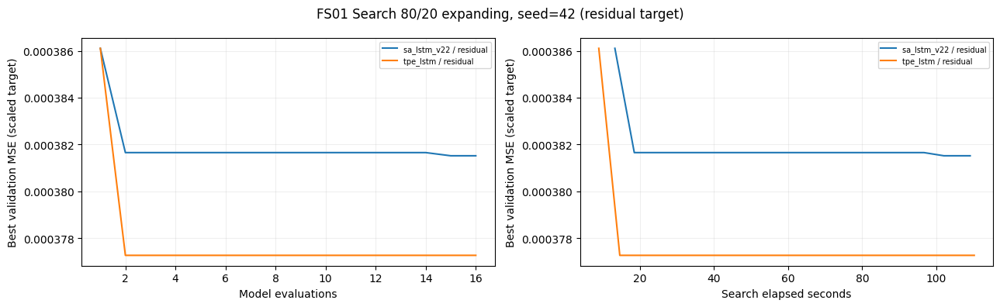

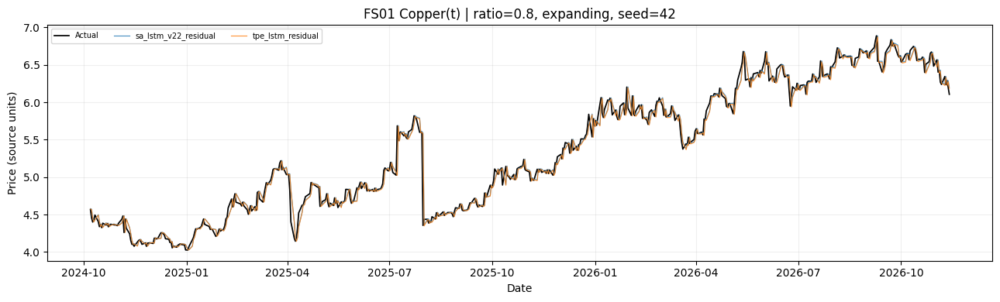

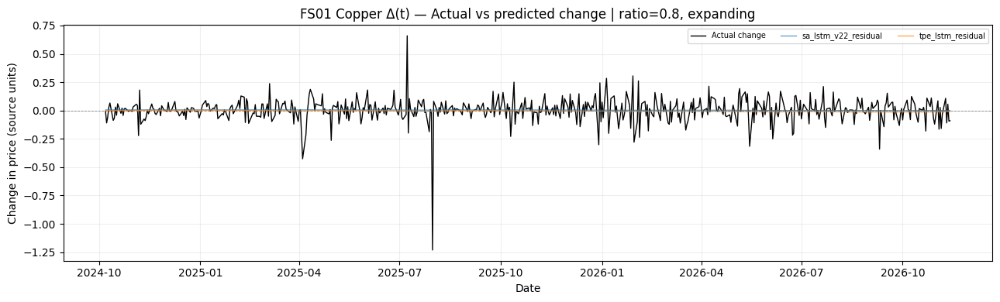

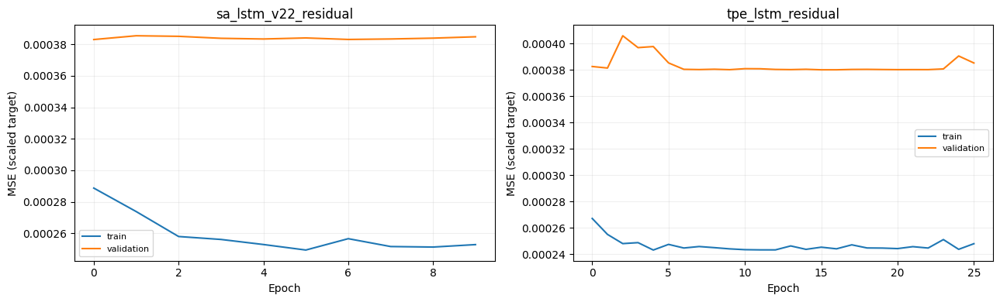

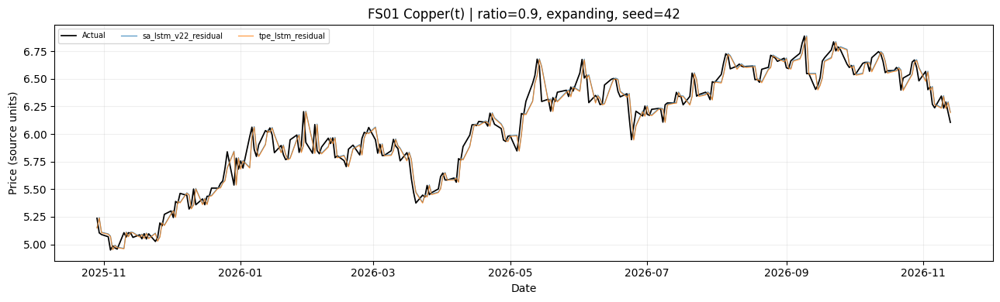

...

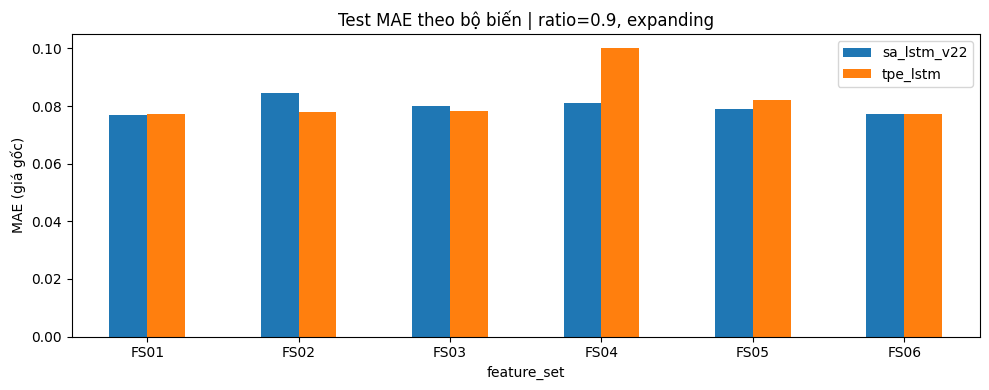

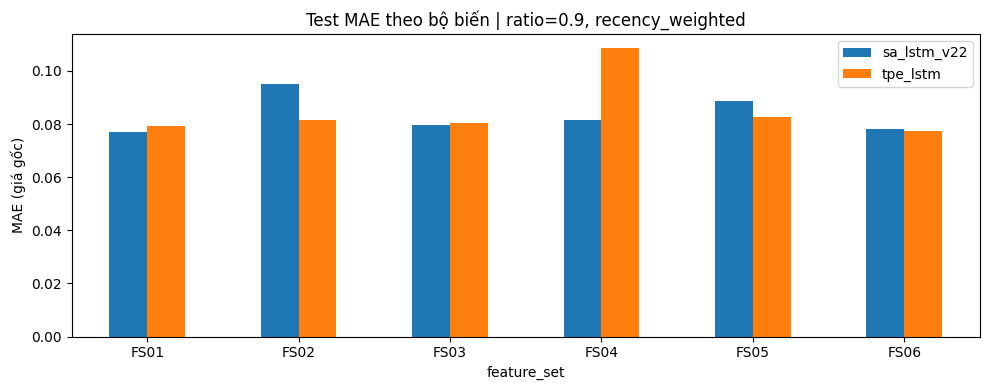

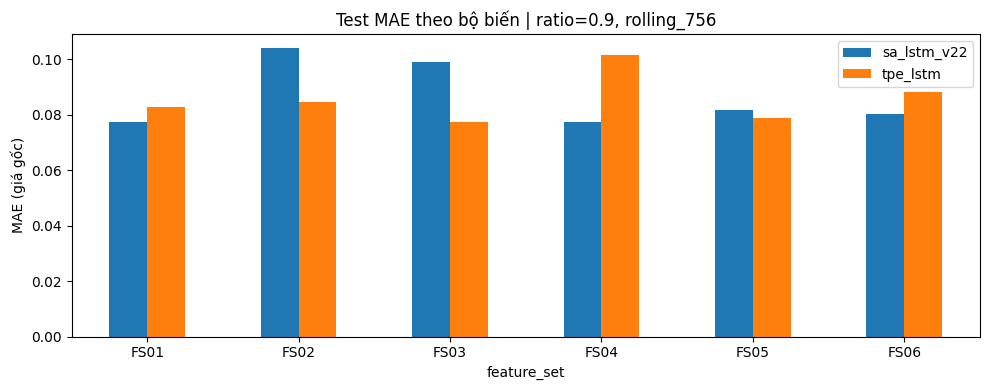

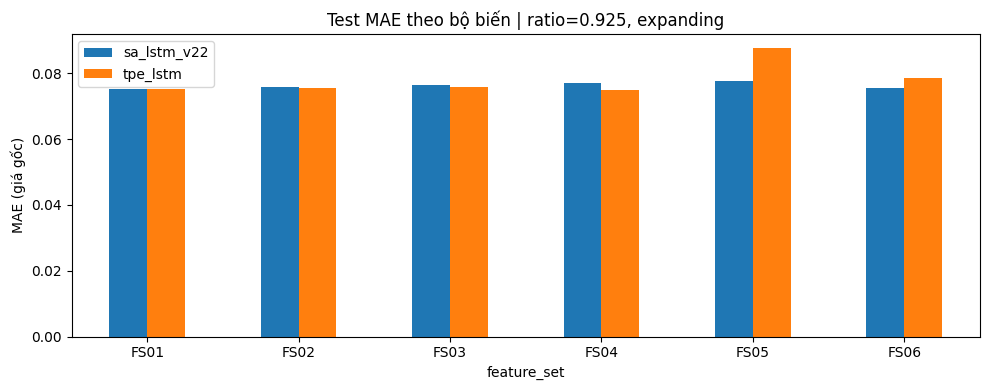

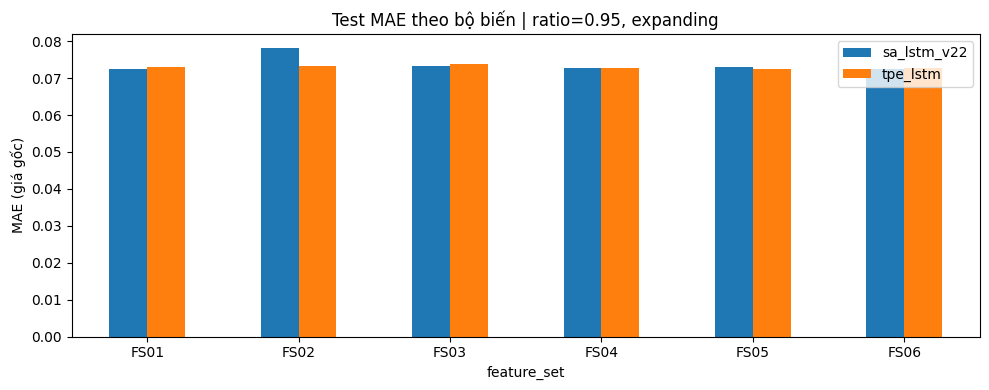

In [16]:
for feature_set in ACTIVE_FEATURE_SETS:
    plot_dir=OUT/feature_set/'figures';plot_dir.mkdir(parents=True,exist_ok=True)
    for seed in SEEDS:
        fig,axs=plt.subplots(1,2,figsize=(13,4))
        for (mode,method),g in search_trials[(search_trials.seed==seed)&(search_trials.feature_set==feature_set)].groupby(['forecast_mode','method']):
            g=g.sort_values('trial');label=f'{method} / {mode}'
            axs[0].plot(g.trial,g.best_val_mse_scaled,label=label)
            axs[1].plot(g.elapsed_seconds,g.best_val_mse_scaled,label=label)
        for ax in axs:
            ax.set_ylabel('Best validation MSE (scaled target)');ax.legend(fontsize=7);ax.grid(alpha=.2)
        axs[0].set_xlabel('Model evaluations');axs[1].set_xlabel('Search elapsed seconds')
        fig.suptitle(f'{feature_set} Search 80/20 expanding, seed={seed} (residual target)')
        fig.tight_layout();fig.savefig(plot_dir/f'search_convergence_{seed}.png',dpi=150)
        plt.show();plt.close(fig)

    for ratio,scheme in JOBS:
        selected=predictions_df[(predictions_df.feature_set==feature_set)&(predictions_df.ratio==ratio)&(predictions_df.scheme==scheme)&
                                (predictions_df.seed==SEEDS[0])]
        ref=selected[selected.model_key==METHOD_LABELS[0]].sort_values('Date')
        fig,ax=plt.subplots(figsize=(13,4))
        ax.plot(ref.Date,ref.actual,color='black',label='Actual',linewidth=1.25)
        for model_key,g in selected.groupby('model_key'):
            g=g.sort_values('Date');ax.plot(g.Date,g.pred,label=model_key,alpha=.8,linewidth=.85)
        ax.set(title=f'{feature_set} Copper(t) | ratio={ratio}, {scheme}, seed={SEEDS[0]}',
               ylabel='Price (source units)',xlabel='Date')
        ax.legend(fontsize=7,ncol=3);ax.grid(alpha=.2);fig.tight_layout()
        fig.savefig(plot_dir/f'prediction_{ratio}_{scheme}.png',dpi=150)
        plt.show();plt.close(fig)

        fig,ax=plt.subplots(figsize=(13,4))
        ax.plot(ref.Date,ref.actual_delta,label='Actual change',color='black',linewidth=1.0)
        for model_key,g in selected.groupby('model_key'):
            g=g.sort_values('Date');ax.plot(g.Date,g.pred_delta,label=model_key,alpha=.78,linewidth=.85)
        ax.axhline(0,linestyle='--',color='gray',linewidth=.6)
        ax.set(title=f'{feature_set} Copper Δ(t) — Actual vs predicted change | ratio={ratio}, {scheme}',
               ylabel='Change in price (source units)',xlabel='Date')
        ax.legend(fontsize=7,ncol=3);ax.grid(alpha=.2);fig.tight_layout()
        fig.savefig(plot_dir/f'delta_prediction_{ratio}_{scheme}.png',dpi=150)
        plt.show();plt.close(fig)

        fig,axs=plt.subplots(1,2,figsize=(13,4))
        for ax,model_key in zip(axs.ravel(),METHOD_LABELS):
            recipe=next(r for r in final_models if r['feature_set']==feature_set and r['model_key']==model_key and
                        r['ratio']==ratio and r['scheme']==scheme and r['seed']==SEEDS[0])
            hist=pd.read_csv(Path(recipe['model_path']).with_name(f'{model_key}_loss.csv'))
            ax.plot(hist.loss,label='train');ax.plot(hist.val_loss,label='validation')
            ax.set(title=model_key,xlabel='Epoch',ylabel='MSE (scaled target)')
            ax.legend(fontsize=8);ax.grid(alpha=.2)
        fig.tight_layout();fig.savefig(plot_dir/f'loss_{ratio}_{scheme}.png',dpi=150)
        plt.show();plt.close(fig)

for (ratio,scheme),part in results_df[results_df.seed==SEEDS[0]].groupby(['ratio','scheme']):
    table=part.pivot(index='feature_set',columns='method',values='mae').reindex(ACTIVE_FEATURE_SETS)
    ax=table.plot.bar(figsize=(10,4),rot=0)
    ax.set(title=f'Test MAE theo bộ biến | ratio={ratio}, {scheme}',ylabel='MAE (giá gốc)')
    ax.legend();ax.figure.tight_layout()
    ax.figure.savefig(OUT/f'feature_sets_mae_{ratio}_{scheme}.png',dpi=150)
    plt.show();plt.close(ax.figure)


## 8. Kết quả

- `manifest.json`: định nghĩa đầy đủ các bộ biến đang chạy, dữ liệu, ngân sách và seeds.
- `metrics_by_run.csv`: 72 dòng kết quả với cả 6 bộ và seed 42; có cột feature_set.
- `paired_comparison_SA_vs_TPE_by_mode.csv`: 36 cặp SA/TPE cùng bộ/ratio/scheme/seed.
- `feature_set_comparison_mae.csv`: bảng đối chiếu MAE các bộ đầu vào.
- `search_comparison.csv`, `all_search_trials.csv`, `locked_best_hyperparameters.json`: search riêng cho từng bộ.
- `data_split_summary.csv`, `final_training.csv`, `test_predictions.csv`, `summary_mean_std.csv` và model/scalers/loss/figures theo thư mục FSxx.
- ZIP chứa toàn bộ kết quả. Một seed có std=NaN; kết quả quick chỉ kiểm tra luồng.


In [17]:
zip_path=OUT.parent/(OUT.name+'_results.zip')
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in sorted(OUT.rglob('*')):
        if file.is_file():z.write(file,arcname=str(file.relative_to(OUT)))
print('Results:',OUT)
print('ZIP:',zip_path)
display(FileLink(str(zip_path)))


Results: /kaggle/working/copper_sa_vs_tpe_six_feature_sets_no_naive/20261121T004726844166Z
ZIP: /kaggle/working/copper_sa_vs_tpe_six_feature_sets_no_naive/20261121T004726844166Z_results.zip


/kaggle/working/copper_sa_vs_tpe_six_feature_sets_no_naive/20261121T004726844166Z_results.zip